<a href="https://colab.research.google.com/github/dev-vighnesh/Tools-Bigdata/blob/main/Project1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 1. Project Overview
This project investigates the temporal and environmental conditions that drive bike-sharing demand. Using exploratory data analysis and statistical inference, we determined that demand is heavily dictated by commuter schedules on working days and seasonal weather changes. While average hourly rentals are statistically higher on working days (193 bikes/hour) compared to non-working days (181 bikes/hour), the more critical operational insight is the distribution of demand: working days experience extreme spikes during rush hours (8 AM and 5-6 PM). Furthermore, there is overwhelming statistical and practical evidence that warmer seasons (Fall/Season 3) drastically increase the likelihood of "high-demand" hours compared to colder seasons (Spring/Season 1). Operations must dynamically reallocate bikes based on daily commuter peaks and scale the total fleet size across different seasons.

# 2. Dataset and Research Questions
 **Dataset Overview**: This analysis uses the **hour.csv** dataset from the UCI Machine Learning Repository.

**Observation Definition**: One observation (row) represents exactly one hour of a specific day in 2011 or 2012, capturing the total number of bike rentals and the environmental/temporal conditions for that hour.

**Research Questions**:
1. How does the time of day and the working day status affect overall bike demand?
2. Is there a statistically significant difference in average hourly rentals between working and non-working days?
3. Does the proportion of "high-demand" hours change significantly between the warmest and coldest seasons?

# 3. Data Preparation

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

#reading the csv file
df = pd.read_csv('hour.csv')

#checking for any messy data
print("Total missing:", df.isnull().sum().sum())
print("Total duplicates:", df.duplicated().sum())

#keeping track of column types for later:
#time related: dteday, hr, mnth, yr
#categorical: season, holiday, weekday, workingday, weathersit
#numeric: temp, atemp, hum, windspeed, casual, registered, cnt

#setting up a binary column for the stats section
#I'm going with > 400 rentals as the threshold for a "busy hour"
#since that isolates roughly the top 15% of the peaks.
df['high_demand'] = (df['cnt'] > 400).astype(int)

#making sure the new column appended correctly
display(df.head())

Total missing: 0
Total duplicates: 0


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt,high_demand
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16,0
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40,0
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32,0
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13,0
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1,0


# 4. Exploratory Data Analysis

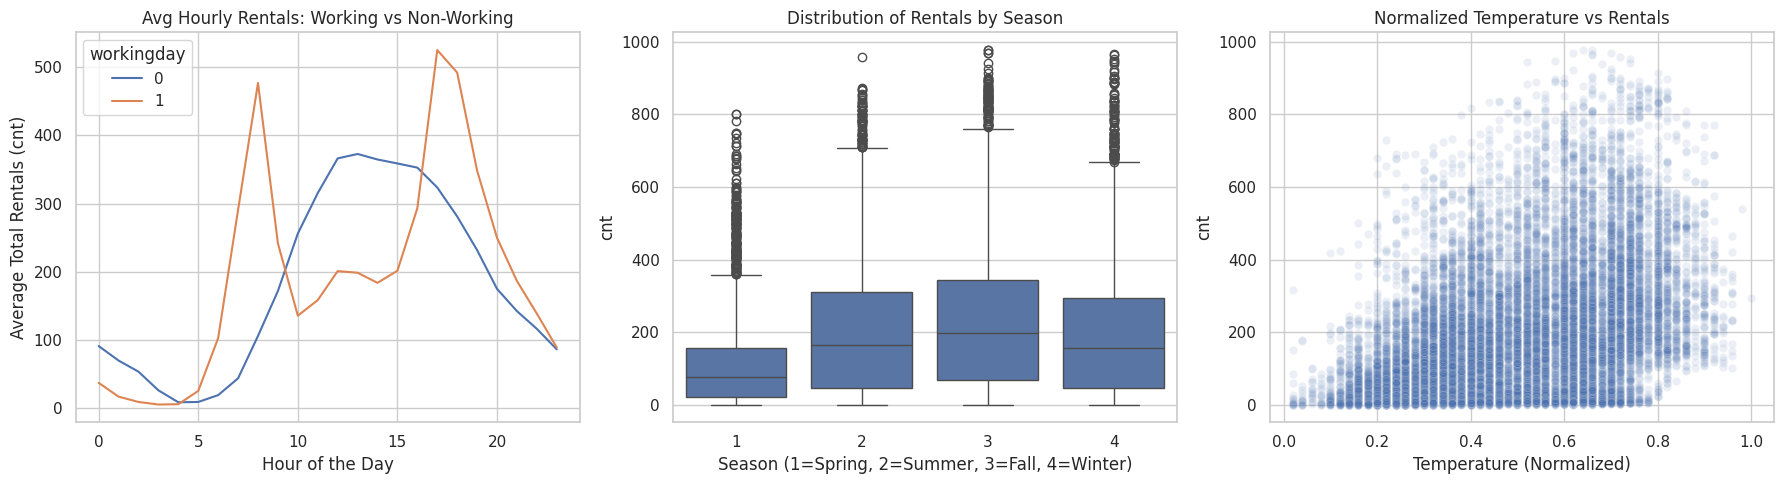

In [6]:
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

#Plot 1: Working vs Non-Working Days
sns.lineplot(data=df, x='hr', y='cnt', hue='workingday', ax=axes[0], errorbar=None)
axes[0].set_title('Avg Hourly Rentals: Working vs Non-Working')
axes[0].set_xlabel('Hour of the Day')
axes[0].set_ylabel('Average Total Rentals (cnt)')

#Plot 2: Demand by Season (1:Spring, 2:Summer, 3:Fall, 4:Winter)
sns.boxplot(data=df, x='season', y='cnt', ax=axes[1])
axes[1].set_title('Distribution of Rentals by Season')
axes[1].set_xlabel('Season (1=Spring, 2=Summer, 3=Fall, 4=Winter)')

#Plot 3: Temperature vs Rentals
sns.scatterplot(data=df, x='temp', y='cnt', alpha=0.1, ax=axes[2])
axes[2].set_title('Normalized Temperature vs Rentals')
axes[2].set_xlabel('Temperature (Normalized)')

plt.tight_layout()
plt.show()

**Exploratory Data Analysis Takeaways:**
* **Plot 1 (Working Days vs Time)**: Commuter patterns heavily dictate demand. Working days (1) show sharp, intense peaks at 8 AM and 5 PM. Non-working days (0) display a gradual bell curve peaking in the early afternoon.
* **Plot 2 (Seasonality)**: Season 3 (Fall/Warmest in this dataset) has the highest median rentals and maximum peaks, while Season 1 (Spring/Coldest) has the lowest demand overall.
* **Plot 3 (Temperature)**: There is a clear positive trend between normalized temperature and total rentals, indicating higher usage in warmer weather.

# 5. Statistical Analysis

### A. Difference Between Two Means
**Research Question**: Is there a statistically significant difference in the average hourly bike rentals between working days and non-working days?

**Population Parameters**:
* $\mu_1$: The true mean hourly bike rentals on working days.
* $\mu_2$: The true mean hourly bike rentals on non-working days.

**Hypotheses**:
* **Null Hypothesis ($H_0$)**: $\mu_1 - \mu_2 = 0$ (No difference).
* **Alternative Hypothesis ($H_A$)**: $\mu_1 - \mu_2 \neq 0$ (There is a difference).

In [7]:
# A. Difference Between Two Means (Welch's t-test)
work_cnt = df[df['workingday'] == 1]['cnt']
non_work_cnt = df[df['workingday'] == 0]['cnt']

#Using t-test (equal_var=False)
t_stat, p_val_t = stats.ttest_ind(work_cnt, non_work_cnt, equal_var=False)

print("--- A. Two Means Test Results ---")
print(f"Working Day Mean: {work_cnt.mean():.2f}")
print(f"Non-Working Day Mean: {non_work_cnt.mean():.2f}")
print(f"T-Statistic: {t_stat:.2f}, P-value: {p_val_t:.5e}\n")

--- A. Two Means Test Results ---
Working Day Mean: 193.21
Non-Working Day Mean: 181.41
T-Statistic: 4.10, P-value: 4.24948e-05



### B. Difference Between Two Proportions
**Research Question**: Is the proportion of high-demand hours (>400 rentals) significantly different between Season 3 (warmest) and Season 1 (coldest)?

**Population Parameters**:
* $p_1$: The true proportion of high-demand hours in Season 3.
* $p_2$: The true proportion of high-demand hours in Season 1.

**Hypotheses**:
* **Null Hypothesis ($H_0$)**: $p_1 - p_2 = 0$
* **Alternative Hypothesis ($H_A$)**: $p_1 - p_2 \neq 0$

In [8]:
# B. Difference Between Two Proportions
summer_hd = df[df['season'] == 3]['high_demand']
winter_hd = df[df['season'] == 1]['high_demand']

p1 = summer_hd.mean()
p2 = winter_hd.mean()
n1, n2 = len(summer_hd), len(winter_hd)

#Z-test calculations
p_pool = (summer_hd.sum() + winter_hd.sum()) / (n1 + n2)
se = np.sqrt(p_pool * (1 - p_pool) * (1/n1 + 1/n2))
z_stat = (p1 - p2) / se
p_val_z = 2 * (1 - stats.norm.cdf(abs(z_stat)))

print("--- B. Two Proportions Test Results ---")
print(f"Season 3 High-Demand Prop (p1): {p1:.3f}")
print(f"Season 1 High-Demand Prop (p2): {p2:.3f}")
print(f"Difference (p1 - p2): {(p1 - p2):.3f}")
print(f"Z-Statistic: {z_stat:.2f}, P-value: {p_val_z:.5e}\n")

--- B. Two Proportions Test Results ---
Season 3 High-Demand Prop (p1): 0.189
Season 1 High-Demand Prop (p2): 0.038
Difference (p1 - p2): 0.150
Z-Statistic: 21.98, P-value: 0.00000e+00



### C. One Additional Inferential Question
**Method Chosen**: Correlation Coefficient.

**Research Question**: Is there a statistically significant linear correlation between normalized temperature and hourly bike rentals?

**Hypotheses**:
* **Null Hypothesis ($H_0$)**: $r = 0$ (No linear correlation).
* **Alternative Hypothesis ($H_A$)**: $r \neq 0$ (Linear correlation exists).

In [9]:
# C. Correlation Test
r_stat, p_val_r = stats.pearsonr(df['temp'], df['cnt'])

print("--- C. Correlation Test Results ---")
print(f"Correlation (r): {r_stat:.3f}")
print(f"P-value: {p_val_r:.5e}")

--- C. Correlation Test Results ---
Correlation (r): 0.405
P-value: 0.00000e+00


# 6. Statistical vs. Practical Significance
* **Two Means Test**: The p-value is near zero, meaning the difference is statistically significant. However, the magnitude of the difference (193 vs 181 average rentals) is only 12 bikes per hour. Operationally, this overall average difference is not practically significant. The time of day matters far more than the daily average.
* **Two Proportions Test**: The difference here is practically massive. In Season 3, nearly 19% of hours are "high-demand", compared to just 3.8% in Season 1. This is a highly significant operational finding that demands business action.

# 7. Assumptions and Limitations
* **Temporal Autocorrelation**: Because this data represents consecutive hours, the observations are not completely independent. A rental count at 8 AM is heavily correlated with the count at 9 AM. This violates the strict independence assumption of standard t-tests and z-tests.
* **Observational Data**: We can only establish statistical associations, not causal relationships. We know warmer temperatures are associated with more rentals, but confounding variables (like daylight hours, school holidays, or tourism spikes) also play a role.

# 8. From Statistical Evidence to Operational Decision
* **Findings**: Warmer seasons (Season 3) have a drastically higher proportion of high-demand hours (18.9%) compared to colder seasons (3.8%).
* **Effect Size & Significance**: The effect is massive (a roughly 5x increase in high-demand probability) and is statistically significant ($p < 0.001$).
* **Practical Meaning**: This is highly meaningful. The infrastructure and fleet size needed in Fall/Summer is significantly different from Spring/Winter.
* **Recommendation**: The operations team should scale down the active bike fleet during Season 1 to save on maintenance and logistics costs, and deploy the maximum fleet during Season 3.
* **Limitations**: The exact start and end dates of weather transitions are unpredictable, making hard calendar cutoffs difficult to schedule perfectly.

# 9. Final Conclusions and Recommendations
**Main Observations**:
Bike demand is split into two distinct behaviors: commuter transit (spikes at 8 AM and 5 PM on weekdays) and leisure transit (smooth afternoon curves on weekends). Temperature and season also heavily dictate overall volume.

**Recommendations for Operations**:
1. **Dynamic Reallocation**: On working days, trucks must actively move bikes to residential areas before 8 AM, and to commercial/office hubs before 5 PM.
2. **Seasonal Scaling**: Fleet size should not remain static year-round. Reduce the active fleet by at least 30% during Season 1 to optimize maintenance resources.
3. **Future Analysis**: Operations should investigate spatial data (start and end stations) to understand exactly *where* these commuter spikes are happening, as hourly volume alone only tells half the story.

